# Figure 1 · (a) published predictors, (b) patch rounds

(a) Mean ASR of each published predictor under the naive (raw input) and corrected (codec reconstruction) reference,
with the range over five attackers. (b) In each patch round, the success rate of that round's attacker against the
predictor it was trained on (R<sub>k-1</sub>), for the EnCodec loop and each space of the multi-space loop.

Recomputes the benchmark (4 jobs) and the in-loop attacks of the main and multi-space loops (6 jobs, 0.5–1 h each;
stored attackers and predictors, no training).

In [1]:
import os, sys
from pathlib import Path

# Find the repository root from wherever the notebook runs (notebooks/ or a subfolder).
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "hackpatch").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("start the notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Markdown, display
from hackpatch import repro

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 200)

In [2]:
# Parameters (also settable through environment variables for non-interactive runs)
# SOURCE = "recompute": re-run the evaluations behind this output from the released checkpoints (GPU), then aggregate.
# SOURCE = "released" : aggregate the released outputs of the original runs (CPU, seconds). This rewrites the
#                       committed analysis/out/ and paper/ files, which should come out identical.
SOURCE = os.environ.get("NB_SOURCE", "recompute")
# RUN = "slurm": one GPU job per run (sbatch), this kernel waits; "local": run in this kernel (needs a GPU).
RUN = os.environ.get("NB_RUN", "slurm")

In [3]:
reg = repro.registry()
KEYS = [k for k, v in reg.items() if v["kind"] in ['bench', 'hnp', 'multispace']]
print(len(KEYS), "runs:", ", ".join(KEYS))

10 runs: hnp_s0, hnp_s1, hnp_s2, ms_s0, ms_s1, ms_s2, bench_sslmos, bench_utmos, bench_nisqa, bench_dnsmos


In [4]:
if SOURCE == "recompute":
    repro.run_keys(KEYS, "recompute", RUN)  # skips runs whose recomputed output already exists
dirs = repro.run_analysis(SOURCE)  # whole analysis chain (seconds); falls back to released outputs where needed
OUT, PAPER = dirs["out"], dirs["paper"]
COMMITTED_OUT, COMMITTED_PAPER = ROOT / "analysis" / "out", ROOT / "paper"

[analysis] runs=/fs/scratch/PAS2301/alialavi/cache/audio_assessment_hackability_release/runs
[analysis] out=/users/PAS2301/alialavi/projects/audio_assessment_hackability/analysis/out
[analysis] paper=/users/PAS2301/alialavi/projects/audio_assessment_hackability/paper


In [5]:
# Where this notebook's inputs came from: recomputed from checkpoints, or released outputs of the original runs.
used = repro.load_registry(repro.results_registry(SOURCE))
pd.Series({k: used[k].get("source", "released") for k in KEYS}, name="source").value_counts()

source
released    10
Name: count, dtype: int64

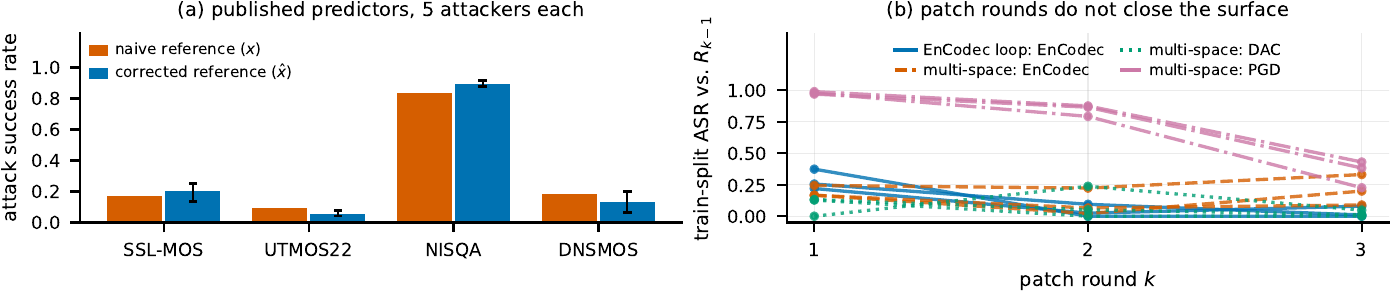

In [6]:
repro.show_pdf(PAPER / "figs" / "results.pdf")

In [7]:
import filecmp
print("figure identical to the committed PDF:",
      filecmp.cmp(PAPER / "figs" / "results.pdf", COMMITTED_PAPER / "figs" / "results.pdf", shallow=False))

figure identical to the committed PDF: True


In [8]:
repro.compare_csv(OUT / "loop_rounds_both_refs.csv", COMMITTED_OUT / "loop_rounds_both_refs.csv")

round            0.0
asr_ref_input    0.0
asr_ref_recon    0.0
recon_gain       0.0
n_pairs          0.0
Name: max_abs_diff, dtype: float64

In [9]:
# Numbers the paper quotes from this output: committed value vs this notebook's value.
cmp = repro.compare_numbers(OUT / "paper_numbers.json", prefixes=('bench_', 'loop_hnp', 'loop_ms'))
print(f"{len(cmp)} numbers; max |diff| = {cmp.abs_diff.max():.4f}; identical: {(cmp.abs_diff == 0).sum()}")
cmp.head(20)

132 numbers; max |diff| = 0.0000; identical: 132


,paper,reproduced,abs_diff
bench_dnsmos_asr_ref_input_mean_2dp,0.180,0.180,0.0
bench_dnsmos_asr_ref_input_mean_3dp,0.183,0.183,0.0
bench_dnsmos_asr_ref_input_mean_pct,18.300,18.300,0.0
bench_dnsmos_asr_ref_input_mean_pct0,18.000,18.000,0.0
bench_dnsmos_asr_ref_recon_max_2dp,0.200,0.200,0.0
bench_dnsmos_asr_ref_recon_max_3dp,0.200,0.200,0.0
bench_dnsmos_asr_ref_recon_max_pct,20.000,20.000,0.0
bench_dnsmos_asr_ref_recon_max_pct0,20.000,20.000,0.0
bench_dnsmos_asr_ref_recon_mean_2dp,0.140,0.140,0.0
bench_dnsmos_asr_ref_recon_mean_3dp,0.136,0.136,0.0
